# J'ai deux passions : geographie et manifestations

## Introduction

Les manifestations du 17 octobre ont été d'une ampleur rare en France. L'anticipation de cet évènement était telle que certain&middot;es ont crié à la "fin de l'époque contemporaine". On sait depuis Siegfried (1913) que d'un territoire à l'autre, l'expression politique change du tout au tout, et que les facteurs géographiques sont déterminants dans la politique française.

Une très grande hypothèse de ce projet est la suivante : les manifestant&middot;es, dans leur grande bonté, ont mis à disposition de notre groupe une cartographie exhaustive des évènements du 17 octobre. Tout évènement déclaré a bien eu lieu ; en retour, tout évènement qui a eu lieu a bien été déclaré. La vérification empirique de cette hypothèse demanderait sûrement un scan exhaustif de la presse régionale - si tant est que celle-ci ait rencensé toutes les manifestations — qui dépasse un peu le cadre de ce travail. On assimilera donc ici déclaration d'évènement à évènement. 

Ce mouvement, qui revêtait au départ un aspect très flou, s'est doté de structures d'organisation pour permettre une mobilisation coordonnée (entre les participant&middot;es, et pas par un organe central). Cela fait peut-être suite au mouvement des Gilets Jaunes : la carte que nous avons étudiée permettait d'émettre un signal crédible de la présence de militant&middot;es.

Le but de ce projet est double. 
- D'une part, il s'agit d'obtenir un aperçu, quoique partiel, des déterminants géographiques des évènements du 17 octobre. Quelles sont les prédicteurs, au niveau local, de la présence d'un évènement ? 
- De l'autre, il s'agit de se demander l'échelle la plus pertinente pour analyser ces phénomènes, dans la continuité des interrogations en géographie économique sur le *Modifiable Aeral Unit Problem* (MAUP). Et si l'échelle retenue affectait grandement la performance des prédicteurs trouvés auparavant ? 

Importation des modules:

In [6]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [7]:
%reload_ext autoreload
%autoreload 2
import pandas as pd
import numpy as np
import folium
import useful.useful_db as udb
import ipywidgets

In [8]:
#pour vérifier quelles fonctions on a :
import importlib
importlib.reload(udb)
print([name for name in dir(udb) if not name.startswith("__")])

['MarkerCluster', 'URL_COMMUNES', 'ajouter_code_insee', 'carte_events', 'carti_download', 'couleur_evenement', 'couleurs_actions', 'desc_bool', 'desc_types_events', 'folium', 'gpd', 'ipywidgets', 'merge_communes', 'np', 'pd']


Importation des bases :

In [9]:
# table qu'on a scrapée
scraped = pd.read_csv(
    "bdd/just17.csv",
    sep=";",
)

# table d'appartenance des communes à des zones géographiques
all_communes = pd.read_excel(
    "bdd/table-appartenance-geo-communes-2026.xlsx",
    header=5,
    dtype=str,
    engine="calamine",
)



## Aperçu des données

### Valeurs manquantes

Nous avons scrapé ce [site](https://www.17octobregiletjaune.net/carte/17-octobre/), créé par Benjamin Ball, qui permettait à chacun&middot;e de renseigner un point de manifestation pour le 17 octobre, et de se déclarer comme participant&middot;e aux dites manifestations. Ces manifestations sont renseignées dans le fichier `nom de fichier.csv`. Un aperçu rapide de la table donne :

In [10]:
scraped.head(5)
print(f"Cette table contient {len(scraped)} lignes, correspondant à autant d'évènements.")
print(scraped.columns)


Cette table contient 2237 lignes, correspondant à autant d'évènements.
Index(['id', 'title', 'time', 'date', 'amount', 'ville', 'gazole', 'cp', 'maj',
       'nom', 'exploitant', 'adresse', 'lat', 'dep', 'e10', 'annonce', 'heure',
       'commune', 'rondpoint', 'lon', 'genre'],
      dtype='str')


On enlève les sites pour lesquels on n'a pas de coordonnées, qui ne pourront de toute façon pas être utilisées

In [11]:
scraped_cleaned = scraped.dropna(subset=["lat","lon"])
print(f"Il y a {len(scraped_cleaned)} lignes où sont renseignées des coordonnées géographiques.")

scraped_dirty = scraped[scraped["lat"].isna()|scraped["lon"].isna()]
print(f"Il y a {len(scraped_dirty)} lignes où ne sont pas renseignées de coordonnées géographiques.")



Il y a 2009 lignes où sont renseignées des coordonnées géographiques.
Il y a 228 lignes où ne sont pas renseignées de coordonnées géographiques.


Penchons nous de plus près sur ces lignes sans coordonnées :

In [12]:
nb_villes = scraped_dirty["ville"].notna().sum()
print(f"Il y a {nb_villes} lignes où la ville est renseignée.")

Il y a 0 lignes où la ville est renseignée.


Elles nous inquiètent moins désormais : on peut les enlever en toute sécurité.

In [13]:
scraped = scraped_cleaned

### Statistiques et cartes descriptives

Sur le site, les participant&middot;es étaient invité&middot;es à renseigner le type d'évènement qui allait se dérouler. Ces types sont renseigéns dans la colonne `title` :

In [14]:
types_events = scraped["title"].unique().tolist()
types_events_freq = scraped["title"].value_counts(dropna=False)
display(types_events_freq)

title
manifestation         606
rassemblement         434
blocage               291
assemblee             206
rond_point            199
barrage_filtrant      131
operation_escargot     46
autre                  40
pancartes              24
tractage               23
prise_de_parole         6
piquet_de_greve         3
Name: count, dtype: int64

NB: une "opération escargot" correspond à un ralentissement volontaire de la circulation par des automobilistes coordonné&middot;es.

En termes de distribution dans l'espace, voici ce qui apparait :

In [15]:
carte_all_events = udb.carte_events(scraped)
carte_all_events

NB : nous avons choisi de garder les DROM COM dans la plupart de nos cartes, dans un souci d'inclusivité.

Afin de faire des statistiques sur la distribution des évènements en France, on y ajoute le code Insee pour chacune des communes. Pour cela, on essaie de croiser directement avec un fond de carte fourni par etalab à [cette adresse](https://etalab-datasets.geo.data.gouv.fr/contours-administratifs/) :

In [16]:
scraped_insee = udb.ajouter_code_insee(scraped)
print(f"On n'a pas de perte : il y a {len(scraped_insee) - len(scraped)} lignes différentes entre `scraped` et `scraped_insee")

On n'a pas de perte : il y a 0 lignes différentes entre `scraped` et `scraped_insee


On la croise ensuite avec une table avec toutes les communes françaises, fournie par l'Insee.

In [17]:
all_communes_events = udb.merge_communes(scraped_insee, all_communes)
len(all_communes_events)

35737

Cela nous permet de faire des statistiques à l'échelle de la France. 

In [18]:
udb.desc_types_events(all_communes_events)

,Effectif,Proportion (%)
Par types d'évènements,,
NaN,33751,94.4
Manifestation,597,1.7
Rassemblement,425,1.2
Blocage,289,0.8
Assemblee,206,0.6
Rond point,198,0.6
Barrage filtrant,129,0.4
Operation escargot,46,0.1
Autre,40,0.1


In [19]:
udb.desc_bool(all_communes_events)

,Effectif,Proportion (%)
has_event,,
Sans événement,33751,96.78
Avec événement,1124,3.22


In [20]:
import sys
sys.path.append("/home/onyxia/work/python_manifestation_explosion/useful")
import chloroplethe_stat_des as chp

# Carte réactive
chp.carte_choroplethe_departements(scraped)

In [21]:
import sys
sys.path.append("/home/onyxia/work/python_manifestation_explosion/useful")
import chloroplethe_stat_des as chp

# Variante avec échelle log si quelques départements écrasent les autres
chp.carte_choroplethe_departements(scraped, )


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

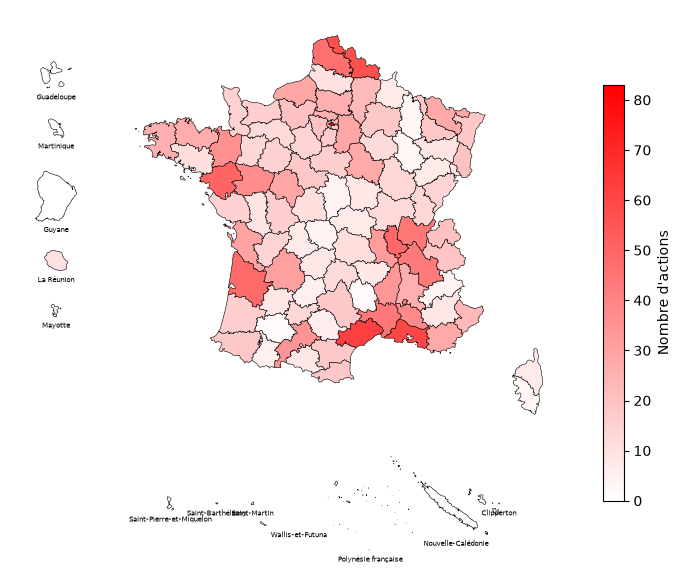

In [22]:
import sys
sys.path.append("/home/onyxia/work/python_manifestation_explosion/useful")
import chloroplethe_stat_des as chp

# Version statique
chp.carte_choroplethe_statique(scraped)

In [23]:
from carte_colore_commune import carte_choroplethe_interactive

m = carte_choroplethe_interactive(
    scraped,
    niveau="commune",
    echelle="log",
    uniquement_actifs=True,
)
m

## Impact des variables socio-démographiques

## Quelle échelle ?

Le MAUP est un problème qui se pose en premier lieu à celui ou celle qui tente de donner des explications aux phénomènes géographiques. Il est prouvé depuis que l'échelle de l'analyse change les résultats, et ce de deux manières (Briant et al., 2010) : 
- l'agglomération des zones, c'est-à-dire leur regroupement en des ensembles plus ou moins grans, change la donne (de la commune, au département, à la région)
- la forme des zones, c'est-à-dire le découpage de ces zones (commune VS zone d'emploi)

Schématiquement, cela donne : 

![Fig 1 : Briant et al., 2010](modele_echelle/MAUP_simple.png)

Nous allons ici essayer de comparer les performances des modèles prédictifs, en fonction des découpages géographiques choisis.

Pour chaque niveau d'agrégation $k$ (par exemple commune, département, région) et chaque unité $i$, on note $Y_i$ le nombre de manifestations (`nb_events`), $P_i$ la population et $x_i$ le prix de l'essence, en centimes. Comme $Y_i$ est un comptage, on estime une régression de Poisson avec lien logarithmique, selon deux spécifications de la moyenne conditionnelle :

1. Modèle avec offset ($\gamma = 1$ imposé, modèle de taux par habitant) :
$$\ln \mathbb{E}[Y_i \mid x_i, P_i] = \ln P_i + \beta_0 + \beta_1 x_i$$

2. Modèle avec $\ln P_i$ libre ($\gamma$ estimé) :
$$\ln \mathbb{E}[Y_i \mid x_i, P_i] = \beta_0 + \beta_1 x_i + \gamma \ln P_i$$

Ces modèles sont particulièrement adaptés au MAUP, car le paramètre $\gamma$ renseigne directement sur la façon dont le nombre de manifestations évolue avec la taille des unités. Si la proportionnalité à la population ($\gamma = 1$) tient à une échelle mais pas à une autre, le modèle avec offset est mal spécifié à cette échelle, et $\hat\beta_1$ peut être biaisé. On compare donc, pour chaque niveau d'agrégation, $\hat\beta_1$ (via $e^{\hat\beta_1}$), $\hat\gamma$ et le test de $H_0 : \gamma = 1$. La stabilité de $\hat\beta_1$ entre échelles et entre spécifications est notre indicateur de robustesse au MAUP.

L'estimation se fait par pseudo-maximum de vraisemblance de Poisson, convergent dès que la moyenne conditionnelle est bien spécifiée, avec des écarts-types robustes (HC3). Pour tester l'effet de zonage, on peut en outre répéter l'estimation sur des découpages alternatifs de même échelle et observer la dispersion de $\hat\beta_1$.

**Limites.** Les coefficients sont des associations conditionnelles et non des effets causaux (que sont dans les cours des prochaines semaines en économétrie). Les écarts-types ne sont pas directement comparables d'une échelle à l'autre, puisque le nombre d'unités change (et avec lui la puissance des tests). Enfin, l'indépendance entre unités est une hypothèse discutable, d'autant plus que les unités sont petites et voisines.

In [27]:
import modele_echelle.preprocessing as pp
import statsmodels.formula.api as smf
import statsmodels.formula as sm

### Par taille de la zone

Intéressons-nous d'abord à la taille de la zone retenue. On peut ici faire des `group_by` à différentes échelles, pour voir les effets des agglomérations. Pour effectuer nos régressions, on utilise des modèles de Poisson, qui permettent de modéliser les comptages. 

On le fait donc au niveau du département, en préparant d'abord la table de notre échantillon :

In [32]:
table_dep = pp.table_reg_essence_prix(all_communes_events, 'DEP').dropna().sort_values(by="nb_events")
display(table_dep.head(10))

,nb_events,prix moyen
DEP,,
05,4,231.400000
65,5,221.900000
08,7,233.300000
03,7,232.550000
09,8,227.900000
58,8,226.825000
43,8,223.400000
04,8,226.733333
79,9,222.400000


Il semble que l'on n'ait pas de données renseignées sur le site quant aux prix de l'essence dans les DROM COM. 

Maintenant, pour la région :

In [33]:
table_region = pp.table_reg_essence_prix(all_communes_events, 'REG').dropna().sort_values(by="nb_events")
display(table_region.head(10))


,nb_events,prix moyen
REG,,
28,91,222.904286
24,92,225.748016
53,99,222.047078
27,104,228.710714
52,130,223.257340
44,136,229.530208
93,161,224.718531
32,163,222.402245
75,209,225.766886


On fait maintenant des régressions linéaires en utilisant `statsmodels` :

### Par forme de la zone